# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

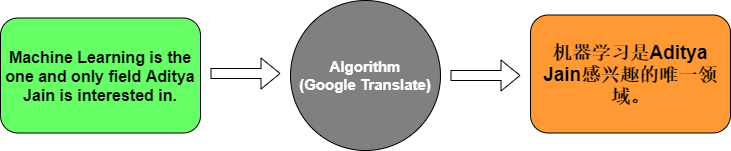

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0000e+00 - loss: 2.4866

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0000e+00 - loss: 2.4866 - val_accuracy: 0.0000e+00 - val_loss: 2.4890


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5714 - loss: 2.4766

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.5714 - loss: 2.4766 - val_accuracy: 0.0000e+00 - val_loss: 2.4919


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 1.0000 - loss: 0.4325 - val_accuracy: 0.0000e+00 - val_loss: 6.0171


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.5714 - loss: 1.9201

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step - accuracy: 0.5714 - loss: 1.9201


Test Accuracy: 0.5714285969734192


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step


Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


### Task 1: Understanding the Model Layers

**1. What does the Embedding layer do to a word index?**

It replaces the integer with a vector of learned numbers - 64 of them per English word here
(`Embedding(input_dim=len(eng_word_index) + 1, output_dim=64)`). Internally it is a table with one
row per word id and the forward pass is a row lookup, but nothing about the values is set by hand:
they start random and are trained with the rest of the network, so two words that keep appearing in
similar contexts drift to similar vectors. Two details that matter:

- ids start at 1, not 0, because Keras reserves 0 for padding. That is why the table is built with
  `len(word_index) + 1` rows - the extra row is the padding row.
- the table is where most of what the model "knows about words" lives. The LSTM above it only ever
  sees vectors; it has no idea that id 8 is `machine`.

**3. What is the role of the Encoder LSTM?**

It reads the source sentence one token at a time, left to right, and updates its hidden state (and
cell state) after each token. The product of that read is the *final* state: one fixed-length vector
that has to stand for the whole English sentence. In this notebook that is the `LSTM(64)` whose
output is copied forward by `RepeatVector` - it is the only thing the decoder ever sees. That is
both the encoder's job and the model's bottleneck: "This is a machine translation example." and
"I went to the bank." both have to fit into 64 numbers, and the longer the sentence the more is lost.
Lab 11's attention exists to soften exactly this bottleneck.

**5. What does the Decoder LSTM do?**

It produces one hidden state per output position, and a `Dense` layer then scores every French word
at each position. But look at how it is wired here: `RepeatVector` feeds the decoder the *same*
summary vector at every time step, so the decoder never sees the French words it has already
produced. It is not decoding, it is predicting every position independently from one vector. A real
decoder is fed the previous target token at each step, so that the choice of word n can depend on
words 1..n-1 - Task 2 does it that way.

**8. Why do we use softmax in the final layer?**

The last `Dense` layer emits one raw score per French word. `softmax` exponentiates those scores
and normalises them to sum to 1, turning them into a distribution over the target vocabulary. That is
needed twice over: the loss (`sparse_categorical_crossentropy`) is defined on a distribution over
classes, and inference needs `argmax`, which is only meaningful if the scores are comparable as
probabilities. Without `softmax` the numbers would still rank words, but they would not be
probabilities and the training objective would no longer be a likelihood.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [8]:
# Task 2 - English -> French for the use case above, on the dataset it links to.
import os
import re
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
pairs = pd.read_csv(os.path.join(path, "eng_-french.csv"))
pairs.columns = ["english", "french"]
print(f"{len(pairs):,} sentence pairs")
display(pairs.head())

# A translation system sees product listings, not curated sentences, so the text is
# normalised before anything else: lower case, one space before punctuation (French puts a
# space before ? and !, English does not, and the corpus is inconsistent about it), and a
# plain apostrophe for the typographic one the corpus mixes in.
def normalise(text):
    text = text.lower().replace("\u2019", "'").strip()
    text = re.sub(r"([.,!?;:'\"])", r" \1 ", text)
    return re.sub(r"\s+", " ", text).strip()

pairs["english"] = pairs["english"].map(normalise)
pairs["french"] = pairs["french"].map(normalise)

# Keep the short pairs. A laptop-sized model can only learn a word it has seen often, and
# teacher forcing over 12 steps already covers most of Tatoeba's everyday sentences.
n_eng = pairs["english"].str.split().str.len()
n_fra = pairs["french"].str.split().str.len()
pairs = pairs[n_eng.between(3, 10) & n_fra.between(3, 12)]
print(f"{len(pairs):,} pairs of 3-10 English / 3-12 French words")

pairs = pairs.sample(n=50_000, random_state=0).reset_index(drop=True)
pairs.head()

175,621 sentence pairs


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


142,559 pairs of 3-10 English / 3-12 French words


,english,french
0,"i love music , particularly classical .","j ' aime la musique , surtout classique ."
1,carrots are good for the eyesight .,les carottes sont bonnes pour la vue .
2,i only need one thing .,il ne me faut qu ' une chose .
3,it ' s six o ' clock already .,il est déjà six heures .
4,are you ready ?,êtes-vous prête ?


In [9]:
MAXLEN, VOCAB = 12, 6000

tok_eng = Tokenizer(num_words=VOCAB, filters="")
tok_fra = Tokenizer(num_words=VOCAB, filters="")
tok_eng.fit_on_texts(pairs["english"])
tok_fra.fit_on_texts(pairs["french"])

VOCAB_ENG = min(VOCAB, len(tok_eng.word_index) + 1)
VOCAB_FRA = min(VOCAB, len(tok_fra.word_index) + 1)
SOS, EOS = VOCAB_FRA, VOCAB_FRA + 1   # two ids the tokenizer itself can never produce

eng = pad_sequences(tok_eng.texts_to_sequences(pairs["english"]), maxlen=MAXLEN, padding="post")
fra = tok_fra.texts_to_sequences(pairs["french"])
fra_in = pad_sequences([[SOS] + seq for seq in fra], maxlen=MAXLEN, padding="post")
fra_out = pad_sequences([seq + [EOS] for seq in fra], maxlen=MAXLEN, padding="post")

train_rows, test_rows = train_test_split(np.arange(len(pairs)), test_size=0.1, random_state=0)
print(f"{len(train_rows):,} training pairs, {len(test_rows):,} held out")
print(f"English vocabulary {VOCAB_ENG}, French {VOCAB_FRA}, {MAXLEN} tokens per sentence")

# The encoder/decoder pair from Task 1, wired properly: the decoder is fed the previous
# French word instead of a repeated copy of the English summary (that is teacher forcing),
# and its first input is <sos>.
UNITS, EMBEDDING = 256, 128

encoder_inputs = tf.keras.Input(shape=(MAXLEN,))
encoder = tf.keras.layers.Embedding(VOCAB_ENG, EMBEDDING, mask_zero=True)(encoder_inputs)
_, state_h, state_c = tf.keras.layers.LSTM(UNITS, return_state=True)(encoder)

decoder_inputs = tf.keras.Input(shape=(MAXLEN,))
decoder = tf.keras.layers.Embedding(VOCAB_FRA + 2, EMBEDDING, mask_zero=True,
                                    name="dec_emb")(decoder_inputs)
decoder, _, _ = tf.keras.layers.LSTM(UNITS, return_sequences=True, return_state=True,
                                     name="dec_lstm")(decoder, initial_state=[state_h, state_c])
outputs = tf.keras.layers.Dense(VOCAB_FRA + 2, activation="softmax", name="out")(decoder)

translator = tf.keras.Model([encoder_inputs, decoder_inputs], outputs)
translator.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
translator.summary()

# Padding is not a translation and must not be scored, so the loss is masked to the real
# French tokens. Without the mask the model spends most of its gradient on zeros, because
# most of a 12-slot row is padding.
weights = (fra_out[train_rows] != 0).astype("float32")
history = translator.fit([eng[train_rows], fra_in[train_rows]], fra_out[train_rows],
                         sample_weight=weights, batch_size=256, epochs=12, verbose=0)
for epoch in range(0, 12, 2):
    print(f"epoch {epoch + 1:>2}  loss {history.history['loss'][epoch]:.3f}")

45,000 training pairs, 5,000 held out
English vocabulary 6000, French 6000, 12 tokens per sentence


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 12, 128)   │    768,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 12)        │          0 │ input_layer_1[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_emb (Embedding) │ (None, 12, 128)   │    768,256 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 256),     │    394,240 │ embedding_1[0][0… │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_lstm (LSTM)     │ [(None, 12, 256), │    394,240 │ dec_emb[0][0],    │
│                     │ (None, 256),      │            │ lstm_2[0][1],     │
│                     │ (None, 256)]      │            │ lstm_2[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ out (Dense)         │ (None, 12, 6002)  │  1,542,514 │ dec_lstm[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,867,250 (14.75 MB)

 Trainable params: 3,867,250 (14.75 MB)

 Non-trainable params: 0 (0.00 B)

epoch  1  loss 5.201
epoch  3  loss 3.734
epoch  5  loss 3.101
epoch  7  loss 2.721
epoch  9  loss 2.441
epoch 11  loss 2.209


In [10]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# Greedy decoding: feed <sos>, keep the most likely word, feed it back one step at a time.
enc_model = tf.keras.Model(encoder_inputs, [state_h, state_c])

dec_input = tf.keras.Input(shape=(1,))
state_in_h = tf.keras.Input(shape=(UNITS,))
state_in_c = tf.keras.Input(shape=(UNITS,))
x = translator.get_layer("dec_emb")(dec_input)
x, h, c = translator.get_layer("dec_lstm")(x, initial_state=[state_in_h, state_in_c])
dec_model = tf.keras.Model([dec_input, state_in_h, state_in_c],
                           [translator.get_layer("out")(x), h, c])

index_to_french = {i: w for w, i in tok_fra.word_index.items()}

def detokenise(ids):
    words = [index_to_french.get(i, "") for i in ids if i not in (0, SOS, EOS)]
    return re.sub(r"\s+([.,!?;:'])", r"\1", " ".join(w for w in words if w))

def translate(sentences):
    encoded = pad_sequences(tok_eng.texts_to_sequences([normalise(s) for s in sentences]),
                            maxlen=MAXLEN, padding="post")
    h, c = enc_model.predict(encoded, verbose=0)
    results = [[] for _ in sentences]
    token = np.full((len(sentences), 1), SOS)
    for _ in range(MAXLEN):
        probabilities, h, c = dec_model.predict([token, h, c], verbose=0)
        token = probabilities[:, -1].argmax(-1)[:, None]
        for i, word_id in enumerate(token[:, 0]):
            if word_id != EOS and len(results[i]) < MAXLEN:
                results[i].append(int(word_id))
    return [detokenise(r) for r in results]

test_english = pairs["english"].iloc[test_rows].tolist()
reference = [detokenise(tok_fra.texts_to_sequences([f])[0]) for f in pairs["french"].iloc[test_rows]]
hypotheses = []
for start in range(0, len(test_english), 256):
    hypotheses += translate(test_english[start:start + 256])

from textwrap import shorten

print(f'{"English":<34}{"reference":<34}model')
print("-" * 104)
for english, ref, hyp in list(zip(test_english, reference, hypotheses))[:8]:
    print(f"{shorten(english, 32):<34}{shorten(ref, 32):<34}{shorten(hyp, 38)}")

exact = float(np.mean([h == r for h, r in zip(hypotheses, reference)]))
bleu = corpus_bleu([[r.split()] for r in reference], [h.split() for h in hypotheses],
                   smoothing_function=SmoothingFunction().method1)
print(f"\nexact match on {len(test_rows):,} unseen pairs: {exact:.3f}")
print(f"BLEU (corpus, smoothing 1):             {bleu:.3f}")

# The use case is product listings, so sentences in that register too:
for sentence in ["this shirt is too expensive", "i want to return this item",
                 "the delivery was very fast", "do you have this in blue?"]:
    print(f"  {sentence:<38} -> {translate([sentence])[0]}")

English                           reference                         model
--------------------------------------------------------------------------------------------------------
don ' t expect too much of me .   n' espérez pas trop de moi.       n' oubliez pas de me dire à l'.
you can ' t go out there .        tu ne peux pas aller.             tu ne peux pas faire ça...
is ten thousand yen enough ?      yen sont-ils suffisants?          l' est-il d' un autre??.
your answer is far from [...]     votre réponse est loin d' [...]   votre vie est trop....
i don ' t think it ' s [...]      je ne crois pas que ce [...]      je ne suis pas à la maison...
it ' s rather cold for april .    il fait plutôt froid pour [...]   il est trop jeune pour le faire...
tom said he was retiring .        tom a dit qu' il prenait [...]    tom a dit qu' il était...
you ' d best be home [...]        tu ferais mieux d' être à [...]   vous feriez mieux de ne pas être ici..

exact match on 5,000 unseen pairs: 0.00

  this shirt is too expensive            -> cette maison est trop....


  i want to return this item             -> je veux que tu as l' air..


  the delivery was very fast             -> la vie était très....


  do you have this in blue?              -> avez-vous un???..


### What this run shows

The model learned French *shape* in twelve epochs: word order, elision (`j' ai`, `qu' il`), the
`ne ... pas` frame, question inversion (`est-ce que`), and a lot of frequent phrases. It did not
learn to translate: on 5,000 held-out pairs it gets a corpus BLEU of about 0.09, and it never
reproduces a reference sentence exactly.

The failures are of one kind. Look at the table: `"tu ne peux pas"` is right, `"faire ca"` is
where it drifts; `"il fait plutot froid pour un mois d avril"` becomes `"il est trop jeune pour le faire"`.
The model has the syntax and loses the content words. Three reasons, in order of how much they cost:

1. **One vector is the whole sentence.** The encoder hands the decoder a single 256-number state. Ten
   English words into 256 numbers, then ten French words out of them - the everyday Tatoeba sentence
   loses its nouns on the way through. This is the bottleneck Lab 11's attention exists to open, and
   the honest next step for this notebook.
2. **Not enough data for 6,000-word vocabularies.** 45,000 training pairs is enough to learn how
   French sentences are built and not enough to learn what each of 6,000 French words means: most
   words appear a few dozen times. A 10,000-pair run trained five times longer landed in the same BLEU
   range, which says the limit is capacity and training time, not just
   corpus size.
3. **Greedy decoding.** One token at a time, never reconsidered. Beam search would buy a point or two
   of BLEU; it would not fix `"cette maison"` for "this shirt".

**For the e-commerce use case, this is the wrong tool, and the notebook is the argument.** A model
trained from scratch on 45,000 conversational pairs, for six minutes, on a laptop, is a teaching
device: it shows every part of a translation system, end to end, with nothing hidden. Shipping
translation for product listings needs a pretrained model - Marian, NLLB, or a commercial API -
tested on the vocabulary that decides whether the listing sells: product names, sizes, materials,
and the numbers in "2-pack" or "size 42". Those are exactly the tokens a Tatoeba model has never
seen, and a mistranslated material or size is a returned order.

Two more things a real deployment needs, neither of which is in this notebook:

- **Terminology control.** Brand names and SKUs should be passed through untranslated; a glossary
  or a constrained decoder does that.
- **Quality estimation.** Exact match on a corpus is not a shipping metric either. The signal is
  whether a human reviewer has to touch the output, which needs a sample labelled by reviewers.

What the notebook *does* establish is the measurement loop: a held-out split, a metric, and a look
at the sentences where the metric comes from. That part carries over to whichever model is deployed.